# **Laboratorio 7** 
## **Aprendizaje No Supervisado**
**Nombre:** Plaza López Cesar Manuel

**Carrera:** Ingeniería de Sistemas

## **Punto 1. -**

In [ ]:
import numpy as np
import random
from sklearn.datasets import make_blobs

# 1. Número aleatorio de centroides entre 1 y 20
n_centers = random.randint(1, 20)

# 2. Generar centroides aleatorios manteniendo el rango original [-10, 10]
blob_centers = []
distancia_minima = 3.2  # Distancia equilibrada para rango [-10, 10]

while len(blob_centers) < n_centers:
    candidate = np.random.uniform(-10, 10, size=2)
    if all(np.linalg.norm(candidate - center) > distancia_minima for center in blob_centers):
        blob_centers.append(candidate)

blob_centers = np.array(blob_centers)

# 3. Dispersión aleatoria (desviaciones estándar pequeñas para evitar solapamiento masivo)
blob_std = np.random.uniform(0.2, 0.6, size=n_centers)

# 4. Número aleatorio de puntos por centroide
n_samples_per_cluster = [random.randint(30, 200) for _ in range(n_centers)]

# 5. Generación del dataset
X, y = make_blobs(
    n_samples=n_samples_per_cluster,
    centers=blob_centers,
    cluster_std=blob_std,
    random_state=42
)

print(f"Se generaron {n_centers} clusters.")
print("Coordenadas de los centroides iniciales:")
print(np.round(blob_centers, 2))

Se generaron 14 clusters.
Coordenadas de los centroides iniciales:
[[ 8.34  2.55]
 [ 3.75 -1.56]
 [ 4.54  2.16]
 [-4.94  0.43]
 [ 1.73  6.31]
 [-3.49 -8.31]
 [ 8.07  9.9 ]
 [ 5.81 -6.27]
 [-2.59  3.62]
 [-2.03 -1.35]
 [-9.8  -7.31]
 [ 0.82 -9.41]
 [-1.41 -4.83]
 [-6.97  7.24]]


In [ ]:
print(y)

[ 4  4 10 ...  4  8 10]


In [ ]:
import matplotlib.pyplot as plt

def plot_clusters(X, y=None):
    plt.scatter(X[:, 0], X[:, 1], c=y, s=10, alpha=0.7)
    plt.xlabel("$x_1$", fontsize=14)
    plt.ylabel("$x_2$", fontsize=14, rotation=0)

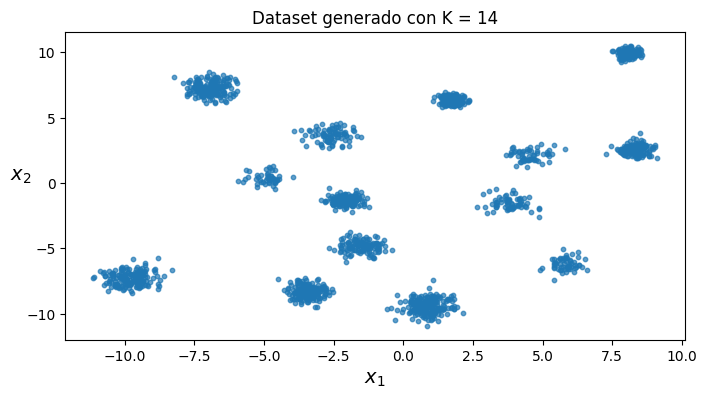

In [ ]:
plt.figure(figsize=(8, 4))
plot_clusters(X)
plt.title(f"Dataset generado con K = {n_centers}")
plt.show()

### **K-Means**

In [ ]:
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
import numpy as np

# 1. Definir K según la cantidad de centroides reales generados
k = len(blob_centers)

# 2. Instanciar y entrenar KMeans
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
y_pred = kmeans.fit_predict(X)

# 3. Obtener la ubicación final de los centroides
centroides_finales = kmeans.cluster_centers_

# 4. Obtener el número de puntos por cada centroide y los 5 más cercanos
puntos_mas_cercanos = {}
conteo_por_centroide = {}

for i in range(k):
    puntos_cluster = X[y_pred == i]
    conteo_por_centroide[i] = len(puntos_cluster)

    # Calcular distancias al centroide actual para extraer los 5 más cercanos
    distancias = cdist(puntos_cluster, [centroides_finales[i]]).flatten()
    indices_top5 = np.argsort(distancias)[:5]
    puntos_mas_cercanos[i] = puntos_cluster[indices_top5]

y_pred

array([ 4,  4,  5, ...,  4, 10,  5], dtype=int32)

In [ ]:
# Definir puntos nuevos para probar la predicción del modelo
X_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])

# Predecir a qué cluster pertenecen estos puntos nuevos
predicciones_nuevas = kmeans.predict(X_new)

print("Predicciones para los puntos nuevos:")
for punto, cluster in zip(X_new, predicciones_nuevas):
    print(f"  Punto {punto} -> Pertenece al Cluster {cluster}")

Predicciones para los puntos nuevos:
  Punto [0. 2.] -> Pertenece al Cluster 10
  Punto [3. 2.] -> Pertenece al Cluster 12
  Punto [-3.  3.] -> Pertenece al Cluster 10
  Punto [-3.   2.5] -> Pertenece al Cluster 10


## **Graficamos fronteras de decisión (los límites entre clusters) y el resultado final.-**


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_centroids(centroids, weights=None, circle_color='w', cross_color='k'):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=60, linewidths=2,
                color=circle_color, zorder=10, alpha=0.9, edgecolors='black')
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=40, linewidths=2,
                color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=500, show_centroids=True,
                             show_xlabels=True, show_ylabels=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]), cmap="Pastel2")
    plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]), linewidths=1, colors='k')
    plot_data(X)

    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)

    # Destacar visualmente los 5 puntos más cercanos a cada centroide en el gráfico
    y_pred = clusterer.labels_
    for i, centroide in enumerate(clusterer.cluster_centers_):
        puntos_cluster = X[y_pred == i]
        distancias = cdist(puntos_cluster, [centroide]).flatten()
        indices_top5 = np.argsort(distancias)[:5]
        top_5_puntos = puntos_cluster[indices_top5]

        plt.scatter(top_5_puntos[:, 0], top_5_puntos[:, 1],
                    s=25, facecolors='none', edgecolors='red', linewidths=1.2, zorder=12)

    if show_xlabels:
        plt.xlabel("$x_1$", fontsize=14)
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", fontsize=14, rotation=0)
    else:
        plt.tick_params(labelleft=False)

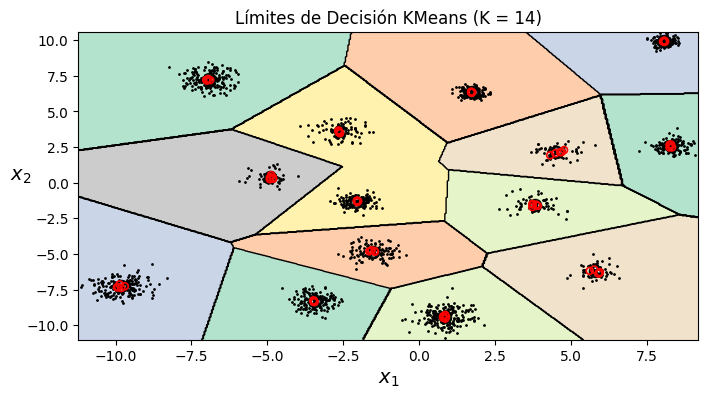

In [ ]:
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans, X)
plt.title(f"Límites de Decisión KMeans (K = {k})")
plt.show()

In [ ]:
# 'soft clustering': Muestra la distancia de cada punto nuevo hacia CADA uno de los centroides
distancias_soft = kmeans.transform(X_new)

print("Matriz de distancias a cada centroide (Soft Clustering):")
print(np.round(distancias_soft, 2))

Matriz de distancias a cada centroide (Soft Clustering):
[[ 8.33 10.86  8.69  7.01  4.68 13.5  11.32 11.44  5.2   3.92  3.07 10.06
   4.53  5.18]
 [ 5.34 12.15 11.23  8.19  4.53 15.82  9.41 11.61  3.63  6.06  5.83  8.67
   1.54  8.08]
 [11.32 11.31  5.79  7.98  5.8  12.33 13.07 13.    8.19  4.43  0.75 12.75
   7.58  3.24]
 [11.31 10.81  6.16  7.49  6.1  11.91 13.34 12.52  7.92  3.94  1.2  12.39
   7.54  2.86]]


In [ ]:
# Entrenar KMeans paso a paso (iteraciones 1, 2 y 3) para observar el proceso de convergencia
kmeans_iter1 = KMeans(n_clusters=k, init="k-means++", n_init=1, algorithm="lloyd", max_iter=1, random_state=42)
kmeans_iter2 = KMeans(n_clusters=k, init="k-means++", n_init=1, algorithm="lloyd", max_iter=2, random_state=42)
kmeans_iter3 = KMeans(n_clusters=k, init="k-means++", n_init=1, algorithm="lloyd", max_iter=3, random_state=42)

kmeans_iter1.fit(X)
kmeans_iter2.fit(X)
kmeans_iter3.fit(X)

KMeans(max_iter=3, n_clusters=14, n_init=1, random_state=42)

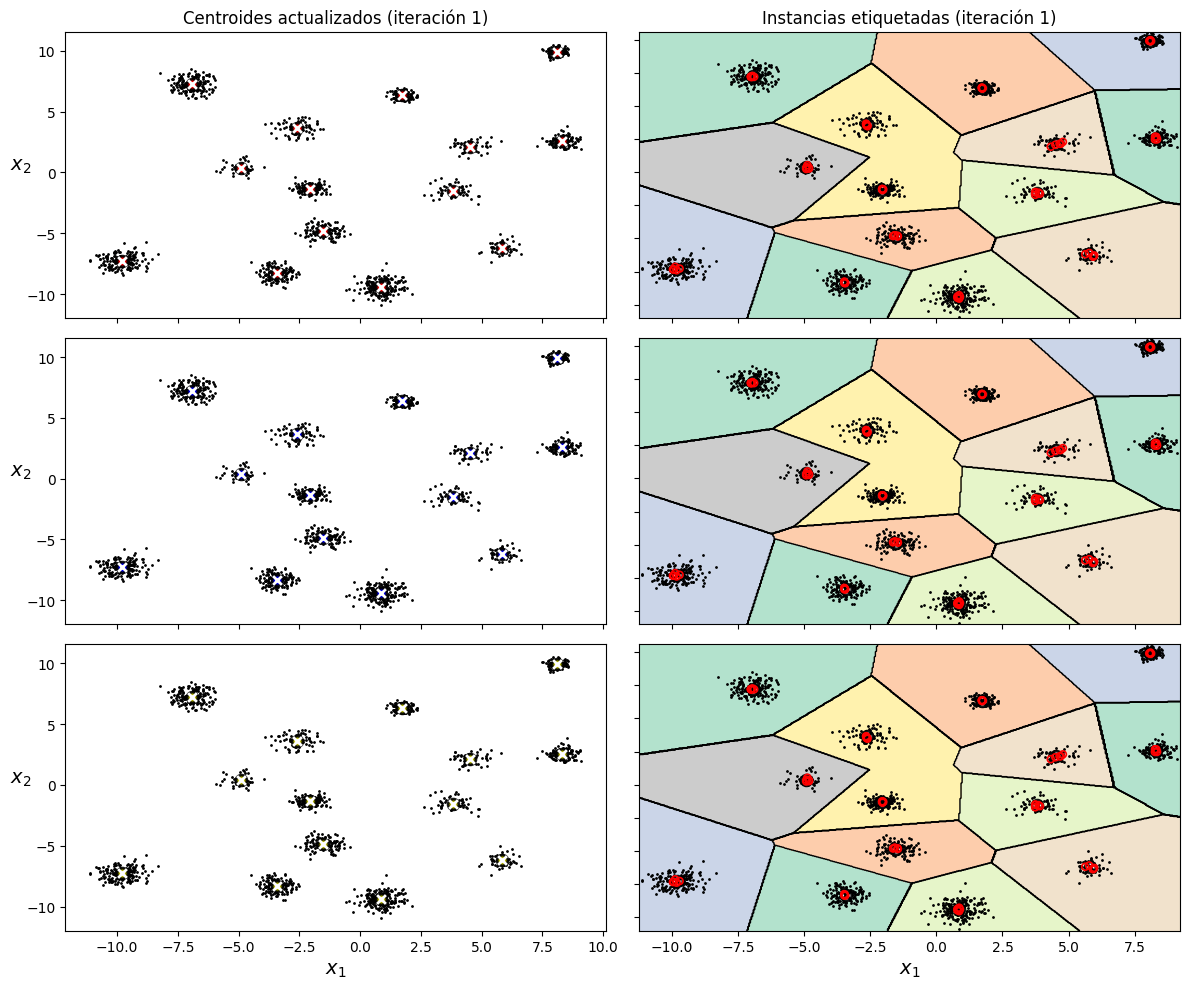

In [ ]:
plt.figure(figsize=(12, 10))

plt.subplot(321)
plot_data(X)
plot_centroids(kmeans_iter1.cluster_centers_, circle_color='r', cross_color='w')
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.tick_params(labelbottom=False)
plt.title("Centroides actualizados (iteración 1)", fontsize=12)

plt.subplot(322)
plot_decision_boundaries(kmeans_iter1, X, show_xlabels=False, show_ylabels=False)
plt.title("Instancias etiquetadas (iteración 1)", fontsize=12)

plt.subplot(323)
plot_data(X)
plot_centroids(kmeans_iter2.cluster_centers_, circle_color='b', cross_color='w')
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.tick_params(labelbottom=False)

plt.subplot(324)
plot_decision_boundaries(kmeans_iter2, X, show_xlabels=False, show_ylabels=False)

plt.subplot(325)
plot_data(X)
plot_centroids(kmeans_iter3.cluster_centers_, circle_color='y', cross_color='w')
plt.xlabel("$x_1$", fontsize=14)
plt.ylabel("$x_2$", fontsize=14, rotation=0)

plt.subplot(326)
plot_decision_boundaries(kmeans_iter3, X, show_ylabels=False)
plt.xlabel("$x_1$", fontsize=14)

plt.tight_layout()
plt.show()

# **Punto 2. -**
## **Generación del Dataset Aleatorio en 3D.-**

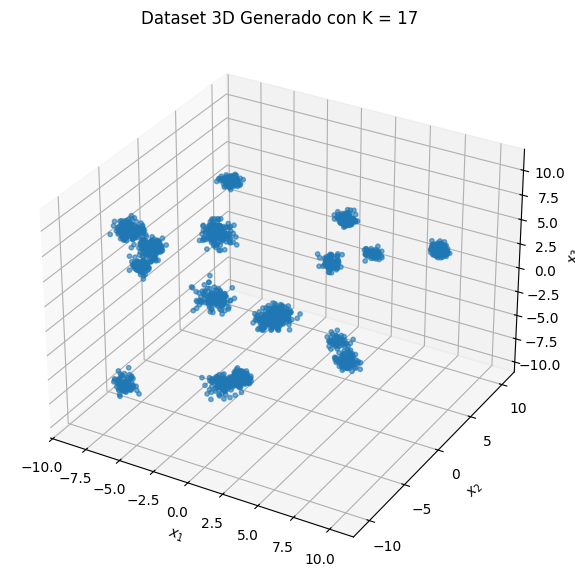

Se generaron 17 clusters en 3D.


In [ ]:
import numpy as np
import random
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

# 1. Número aleatorio de centroides entre 1 y 20
n_centers = random.randint(1, 20)

# 2. Generar centroides aleatorios en 3D dentro del rango [-10, 10]
blob_centers_3d = []
distancia_minima = 4.0  # Distancia para evitar solapamiento en espacio 3D

while len(blob_centers_3d) < n_centers:
    candidate = np.random.uniform(-10, 10, size=3)  # Coordenadas (x1, x2, x3)
    if all(np.linalg.norm(candidate - center) > distancia_minima for center in blob_centers_3d):
        blob_centers_3d.append(candidate)

blob_centers_3d = np.array(blob_centers_3d)

# 3. Dispersión aleatoria por cluster
blob_std = np.random.uniform(0.2, 0.6, size=n_centers)

# 4. Número aleatorio de puntos por centroide
n_samples_per_cluster = [random.randint(30, 200) for _ in range(n_centers)]

# 5. Generar dataset 3D con make_blobs
X_3d, y_3d = make_blobs(
    n_samples=n_samples_per_cluster,
    centers=blob_centers_3d,
    cluster_std=blob_std,
    random_state=42
)

# 6. Visualización 3D del Dataset
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_3d[:, 0], X_3d[:, 1], X_3d[:, 2], s=10, alpha=0.6)

ax.set_title(f"Dataset 3D Generado con K = {n_centers}")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$x_3$")

plt.show()

print(f"Se generaron {n_centers} clusters en 3D.")

##**Entrenar KMeans 3D y extraer centroides/5 puntos más cercanos. -**

In [ ]:
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist

# 1. Definir K según la cantidad de centroides 3D reales
k = len(blob_centers_3d)

# 2. Instanciar y entrenar KMeans 3D
kmeans_3d = KMeans(n_clusters=k, random_state=42, n_init=10)
y_pred_3d = kmeans_3d.fit_predict(X_3d)

# 3. Centroides finales calculados por el modelo
centroides_finales_3d = kmeans_3d.cluster_centers_

# 4. Calcular conteo y los 5 puntos más cercanos a cada centroide 3D
puntos_mas_cercanos_3d = {}
conteo_por_centroide_3d = {}

for i in range(k):
    puntos_cluster = X_3d[y_pred_3d == i]
    conteo_por_centroide_3d[i] = len(puntos_cluster)

    # Distancias tridimensionales al centroide actual
    distancias = cdist(puntos_cluster, [centroides_finales_3d[i]]).flatten()
    indices_top5 = np.argsort(distancias)[:5]
    puntos_mas_cercanos_3d[i] = puntos_cluster[indices_top5]

print("KMeans 3D entrenado exitosamente.")

KMeans 3D entrenado exitosamente.


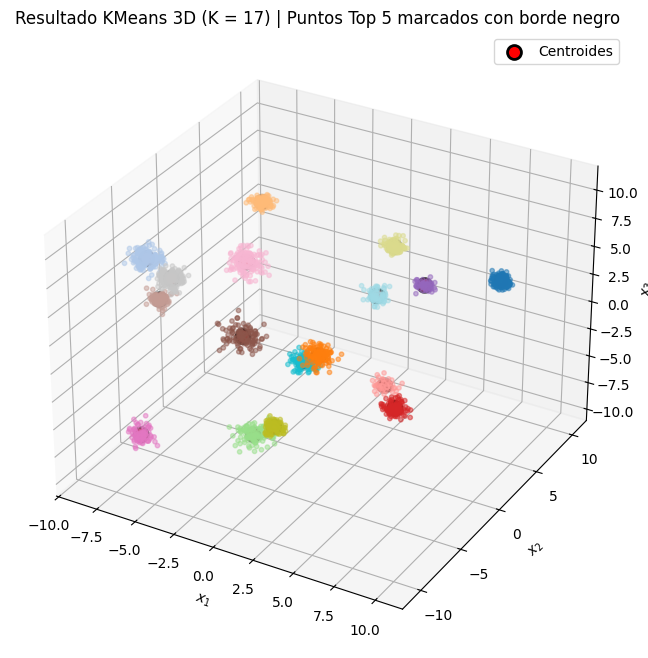

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# 1. Graficar todos los puntos coloreados por cluster
scatter = ax.scatter(X_3d[:, 0], X_3d[:, 1], X_3d[:, 2],
                     c=y_pred_3d, cmap='tab20', s=10, alpha=0.5)

# 2. Graficar los centroides finales (puntos rojos grandes con borde negro)
ax.scatter(centroides_finales_3d[:, 0], centroides_finales_3d[:, 1], centroides_finales_3d[:, 2],
           c='red', marker='o', s=100, edgecolors='black', linewidths=2, label='Centroides', zorder=10)

# 3. Destacar los 5 puntos más cercanos a cada centroide (círculos negros)
for i in range(k):
    top5 = puntos_mas_cercanos_3d[i]
    ax.scatter(top5[:, 0], top5[:, 1], top5[:, 2],
               s=40, facecolors='none', edgecolors='black', linewidths=1.5, zorder=11)

ax.set_title(f"Resultado KMeans 3D (K = {k}) | Puntos Top 5 marcados con borde negro")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$x_3$")
ax.legend()

plt.show()

# **PUNTO 3. -**

## Aprendizaje Semi Supervisado

Dataset Sign Language MNIST
- 27.455 imágenes de entrenamiento.
- 7.172 imágenes de prueba.
- 784 píxeles por imagen, correspondientes a 28 × 28.
- 24 clases presentes en las etiquetas.
Las letras J y Z no están incluidas porque requieren movimiento en el alfabeto representado por este dataset.

In [4]:
import pandas as pd
import numpy as np

# Ruta al archivo CSV de entrenamiento
csv_path = 'sign language mnist/sign_mnist_train/sign_mnist_train.csv'  

print("Cargando datos de Sign Language MNIST desde CSV...")
df = pd.read_csv(csv_path)

# La primera columna ('label') son las etiquetas y el resto son los 784 píxeles
y = df['label'].values
X = df.drop('label', axis=1).values

# Clases únicas presentes en el dataset
target_names = sorted(np.unique(y))

# Verificar las dimensiones
print("Shape de X:", X.shape)
print("Shape de y:", y.shape)
print("Número de clases:", len(target_names))
print("Clases detectadas:", target_names)

Cargando datos de Sign Language MNIST desde CSV...
Shape de X: (27455, 784)
Shape de y: (27455,)
Número de clases: 24
Clases detectadas: [0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


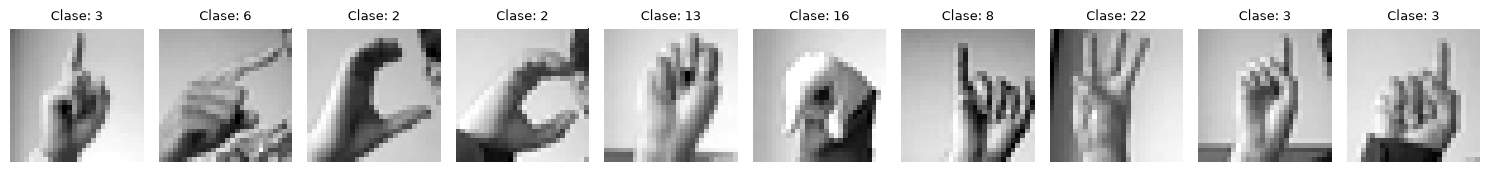

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Mostrar las primeras 10 imágenes del dataset
fig, axes = plt.subplots(1, 10, figsize=(15, 3))

for i in range(10):
    # Rescatar la forma original de la imagen (28x28) a partir del vector plano X[i]
    img_reshaped = X[i].reshape(28, 28)
    
    # imshow con escala de grises
    axes[i].imshow(img_reshaped.astype(np.uint8), cmap='gray')
    axes[i].axis("off")
    
    # Mostrar la etiqueta numérica de la clase
    axes[i].set_title(f"Clase: {y[i]}", fontsize=9)  

plt.tight_layout()
plt.show()

In [7]:
import pandas as pd
import numpy as np

# Cargar directamente los archivos train y test que ya trae el dataset
print("Cargando datos de entrenamiento y prueba...")
train_df = pd.read_csv('sign language mnist/sign_mnist_train/sign_mnist_train.csv')
test_df = pd.read_csv('sign language mnist/sign_mnist_test/sign_mnist_test.csv')

# Separar características (X) y etiquetas (y) para train
X_train = train_df.drop('label', axis=1).values
y_train = train_df['label'].values

# Separar características (X) y etiquetas (y) para test
X_test = test_df.drop('label', axis=1).values
y_test = test_df['label'].values

# NORMALIZACIÓN 
# Convertir a float y dividir entre 255 para llevar los píxeles al rango [0.0, 1.0]
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Dimensiones de X_train:", X_train.shape)
print("Dimensiones de X_test:", X_test.shape)
print("Rango de valores en X_train:", X_train.min(), "a", X_train.max())

Cargando datos de entrenamiento y prueba...
Dimensiones de X_train: (27455, 784)
Dimensiones de X_test: (7172, 784)
Rango de valores en X_train: 0.0 a 1.0


In [28]:
from sklearn.cluster import KMeans

k = 50  # Número de clústeres ajustado a las 24 clases del dataset
kmeans = KMeans(n_clusters=k, random_state=42)
X_train_dist = kmeans.fit_transform(X_train)  # Distancia de cada imagen a cada centroide usando píxeles crudos

print("Shape de distancias:", X_train_dist.shape)

Shape de distancias: (27455, 50)


In [29]:
import numpy as np

idxs = np.argmin(X_train_dist, axis=0)  # índice de la imagen más cercana a cada uno de los 50 centroides

# Guardamos las imágenes representativas puras (en su espacio original de píxeles normalizados)
X_representative_images = X_train[idxs]  

print("Shape de imágenes representativas:", X_representative_images.shape)

Shape de imágenes representativas: (50, 784)


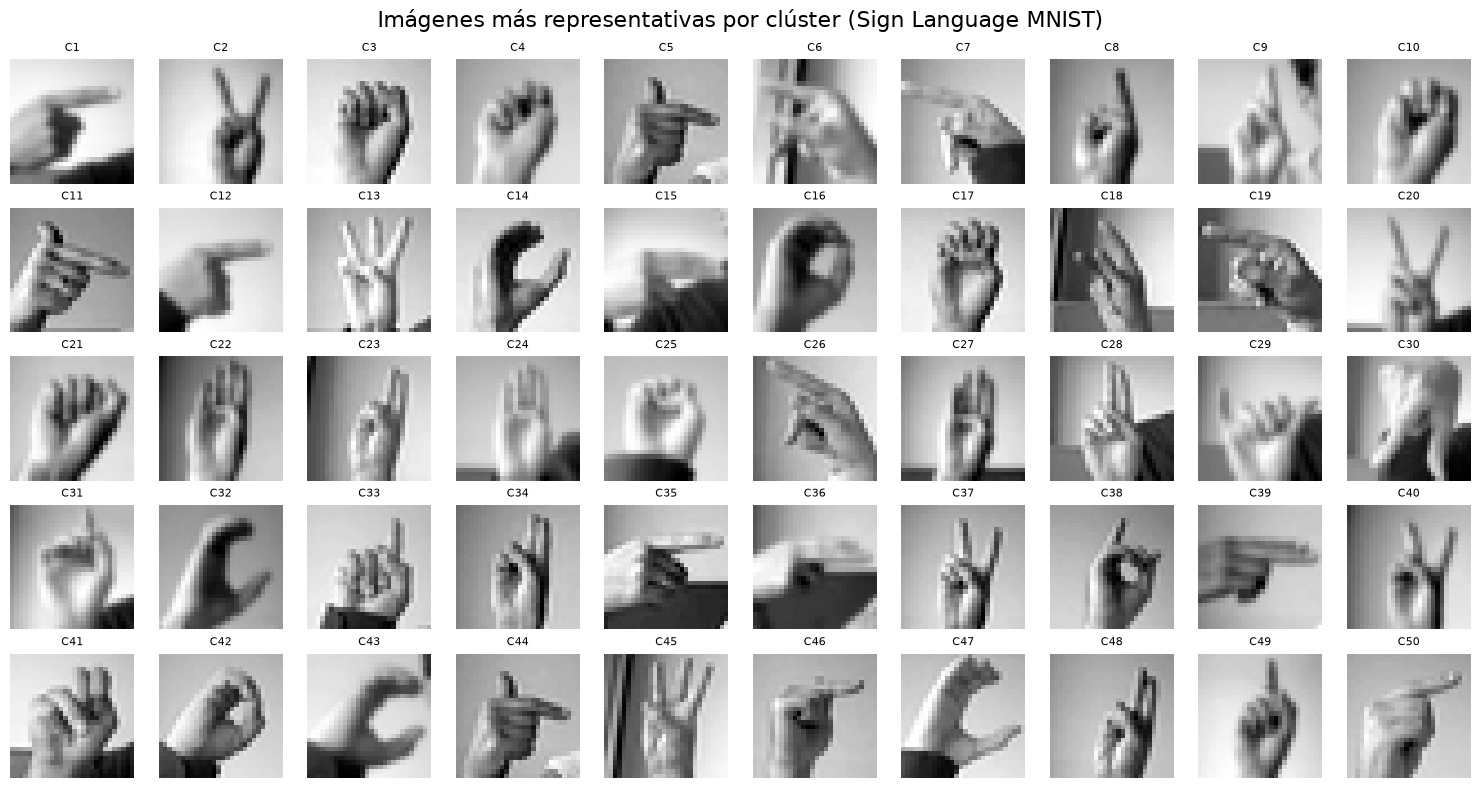

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# Dimensiones de las imágenes de Sign Language MNIST
h, w = 28, 28

plt.figure(figsize=(15, 8))
for index, img_flat in enumerate(X_representative_images):
    plt.subplot(5, 10, index + 1)
    img_reshaped = img_flat.reshape(h, w)  
    plt.imshow(img_reshaped, cmap='gray')                     
    plt.title(f"C{index+1}", fontsize=8)
    plt.axis('off')
    
plt.suptitle("Imágenes más representativas por clúster (Sign Language MNIST)", fontsize=16)
plt.tight_layout()
plt.show()

In [31]:
import numpy as np

# Extraer la etiqueta real del dataset que cayó como representante de cada clúster
y_representative_images = y_train[idxs]

print("Shape de las etiquetas representativas:", y_representative_images.shape)
print("Etiquetas asignadas:", y_representative_images)

Shape de las etiquetas representativas: (50,)
Etiquetas asignadas: [ 6 21 18 13 19 15 15 17 17 12 19  6 22  2  7 14  4 10 15 21  0  1 20  1
  4 15  1 20 24 16  3  2  3 20  6  7 21  3  7 21 13 14  2 19 22 19  2 20
  3  6]


In [32]:
from sklearn.linear_model import LogisticRegression

# Entrenamos el modelo usando directamente las imágenes representativas y sus etiquetas
log_reg2 = LogisticRegression(solver="lbfgs", max_iter=10000, random_state=42)
%time log_reg2.fit(X_representative_images, y_representative_images)  

# Evaluamos el modelo en el conjunto de prueba usando los píxeles crudos normalizados (X_test)
print("Precisión usando solo imágenes representativas (con píxeles crudos):", log_reg2.score(X_test, y_test))

CPU times: total: 9.45 s
Wall time: 2.55 s
Precisión usando solo imágenes representativas (con píxeles crudos): 0.27704963747908534


In [33]:
from sklearn.linear_model import LogisticRegression

# Usamos las primeras 50 imágenes aleatorias de X_train en píxeles crudos
log_reg_random = LogisticRegression(solver="lbfgs", max_iter=10000, random_state=42)
%time log_reg_random.fit(X_train[:50], y_train[:50])

# Evaluamos el modelo en el conjunto de prueba usando X_test
print("Precisión usando 50 imágenes aleatorias (con píxeles crudos):", log_reg_random.score(X_test, y_test))

CPU times: total: 5.64 s
Wall time: 1.61 s
Precisión usando 50 imágenes aleatorias (con píxeles crudos): 0.20482431678750698


In [34]:
from sklearn.linear_model import LogisticRegression
import numpy as np

# Propagación de etiquetas a todo el conjunto de entrenamiento
y_train_propagated = np.empty(len(X_train))
for i in range(k):
    y_train_propagated[kmeans.labels_ == i] = y_representative_images[i]

# ENTRENAR CON TODO X_train (en lugar de solo [:1000])
log_reg3 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)
%time log_reg3.fit(X_train, y_train_propagated)

# Evaluamos usando X_test completo
print("Precisión con todo el dataset semi-etiquetado (píxeles crudos):", log_reg3.score(X_test, y_test))

CPU times: total: 4min 51s
Wall time: 1min 13s
Precisión con todo el dataset semi-etiquetado (píxeles crudos): 0.19813162297824874


## **Aprendizaje Activo.-**

In [35]:
import numpy as np

# Calculamos las probabilidades de las primeras 1000 muestras usando píxeles crudos
probas = log_reg3.predict_proba(X_train[:1000])

# Obtenemos el índice de la clase más probable para cada muestra
labels_ixs = np.argmax(probas, axis=1)

# Obtenemos la confianza (probabilidad máxima) de cada predicción
confidences = probas[np.arange(len(probas)), labels_ixs]

print("Shape de probabilidades:", probas.shape)
print("Shape de confianzas:", confidences.shape)

Shape de probabilidades: (1000, 20)
Shape de confianzas: (1000,)


In [36]:
import numpy as np

# Ordenamos por confianza (de menor a mayor)
sorted_ixs = np.argsort(confidences)

k = 50  # cantidad de muestras "inciertas" a revisar

# Obtenemos las 50 imágenes más inciertas usando píxeles crudos
X_lowest = X_train[:1000][sorted_ixs[:k]]
y_lowest = y_train[:1000][sorted_ixs[:k]]

print("Shape de X_lowest:", X_lowest.shape)
print("Shape de y_lowest:", y_lowest.shape)

Shape de X_lowest: (50, 784)
Shape de y_lowest: (50,)


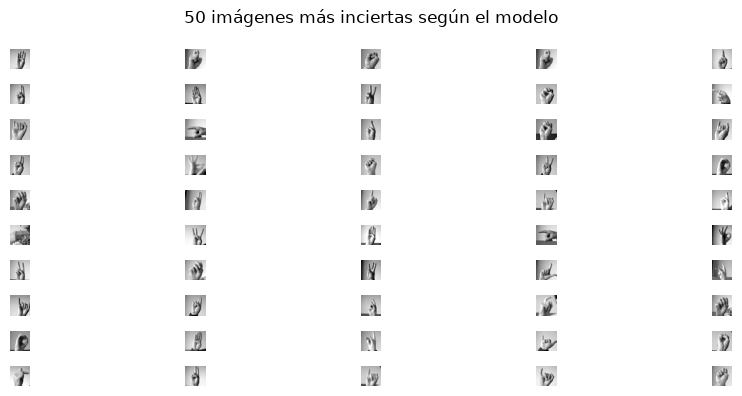

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
for i in range(10):
    for j in range(5):
        idx = i * 5 + j
        image = X_lowest[idx].reshape(28, 28)  # Ajustado a 28x28
        plt.subplot(10, 5, idx + 1)
        plt.imshow(image, cmap="gray")
        plt.axis("off")
plt.suptitle("50 imágenes más inciertas según el modelo")
plt.tight_layout()
plt.show()

In [38]:
from sklearn.linear_model import LogisticRegression

log_reg_active = LogisticRegression(solver="lbfgs", max_iter=10000, random_state=42)

# Entrenamos con las 50 muestras inciertas
%time log_reg_active.fit(X_lowest, y_lowest)

# Evaluamos en el conjunto de prueba
print("Precisión usando aprendizaje activo (50 imágenes inciertas):", log_reg_active.score(X_test, y_test))

CPU times: total: 10.3 s
Wall time: 2.5 s
Precisión usando aprendizaje activo (50 imágenes inciertas): 0.1604852203011712
